In [1]:
!pip install networkx matplotlib numpy pandas gensim scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 8.2 MB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gensim]2m1/2 [gensim]


In [2]:
#now we are importing the libraries
import networkx as nx #Imports NetworkX to work with graphs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gensim.models import Word2Vec
from sklearn.decomposition import PCA

import random

In [3]:
#load the dataset of lesmiserables
G = nx.les_miserables_graph()

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 77
Number of edges: 254


In [4]:
print("Characters in the network:")

for node in list(G.nodes())[:15]:
    print(node)              #selects the first 15 characters

Characters in the network:
Napoleon
Myriel
MlleBaptistine
MmeMagloire
CountessDeLo
Geborand
Champtercier
Cravatte
Count
OldMan
Valjean
Labarre
Marguerite
MmeDeR
Isabeau


In [5]:
print("Is the graph directed?", G.is_directed())

print("Is the graph connected?", nx.is_connected(G))

print("Number of nodes:", len(G.nodes()))

print("Number of edges:", len(G.edges()))

Is the graph directed? False
Is the graph connected? True
Number of nodes: 77
Number of edges: 254


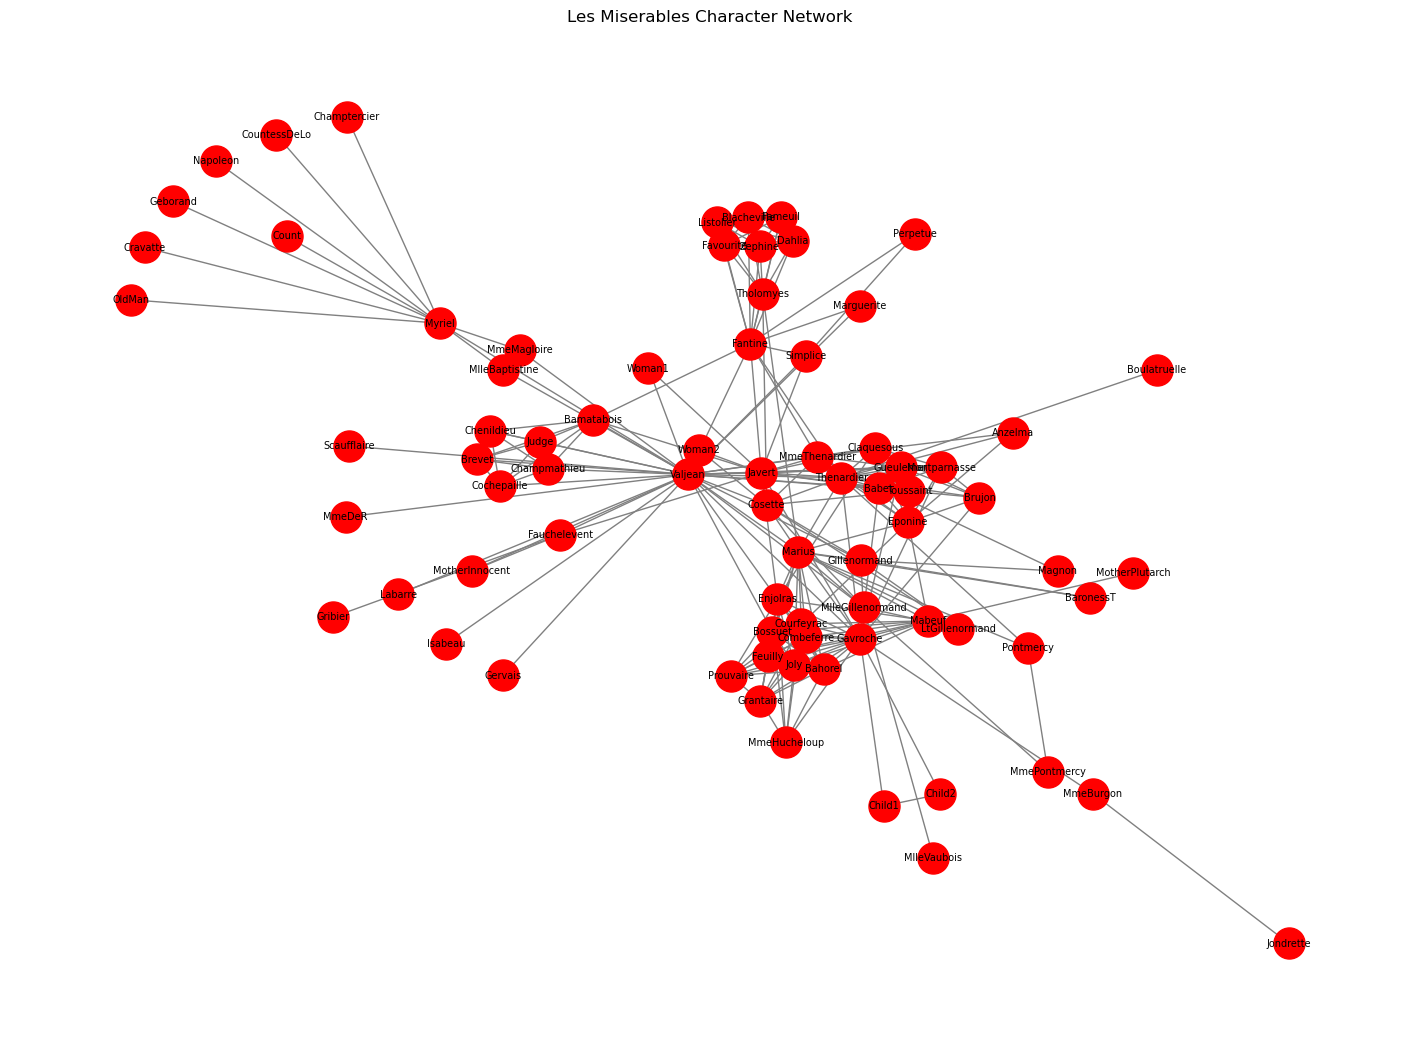

In [6]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="Red",
    node_size=500,
    font_size=7,
    edge_color="gray"
)

plt.title("Les Miserables Character Network")

plt.show()

#we are visualising the graph


In [7]:
# Implement Random Walk
# Main algorithm begins here
# This is the most important part of your assignment.
# What exactly is a random walk?
# Imagine that we start from Jean Valjean.

# The computer looks at all the characters directly connected to him.

# It randomly selects one of them and moves to that character.

# Then it again selects one of the new character's connected neighbours.

In [8]:
def random_walk(graph, start_node, walk_length):
    #walk_length: How many nodes the walk should contain.

    walk = [start_node]

    for i in range(walk_length - 1):

        current_node = walk[-1]

        neighbors = list(graph.neighbors(current_node))

        if len(neighbors) == 0:
            break

        next_node = random.choice(neighbors)

        walk.append(next_node)

    return walk

In [11]:
#test one random walk

random.seed(42)

sample_walk = random_walk(G, "Valjean", 10)

print("Random Walk:")
print(sample_walk)

Random Walk:
['Valjean', 'Gervais', 'Valjean', 'Woman1', 'Valjean', 'Bamatabois', 'Valjean', 'Isabeau', 'Valjean', 'MlleGillenormand']


In [12]:
#test another random walk

random.seed(42)

sample_walk = random_walk(G, "Jondrette", 10)

print("Random Walk:")
print(sample_walk)

Random Walk:
['Jondrette', 'MmeBurgon', 'Jondrette', 'MmeBurgon', 'Jondrette', 'MmeBurgon', 'Jondrette', 'MmeBurgon', 'Jondrette', 'MmeBurgon']


In [13]:

# Generate multiple random walks
# One random walk is not sufficient to understand the entire network.

# We need to generate multiple walks from every character.

# For our implementation, we will use:

# Number of walks per node	10
# Walk length	20
# Total nodes	77
# Total walks	770


random.seed(42)

walks = []

num_walks = 10
walk_length = 20

nodes = list(G.nodes())

for _ in range(num_walks):

    random.shuffle(nodes)

    for node in nodes:

        walk = random_walk(G, node, walk_length)

        walk = [str(n) for n in walk]

        walks.append(walk)

print("Total random walks:", len(walks))

Total random walks: 770


In [14]:
for i in range(5):

    print("Walk", i + 1, ":", walks[i])


    # This displays five generated sequences

Walk 1 : ['Woman1', 'Javert', 'Thenardier', 'Pontmercy', 'Marius', 'Thenardier', 'Pontmercy', 'MmePontmercy', 'Pontmercy', 'MmePontmercy', 'MlleGillenormand', 'LtGillenormand', 'Cosette', 'MmeThenardier', 'Cosette', 'MmeThenardier', 'Eponine', 'Gueulemer', 'Gavroche', 'Javert']
Walk 2 : ['Jondrette', 'MmeBurgon', 'Gavroche', 'Enjolras', 'Bossuet', 'Combeferre', 'Courfeyrac', 'Joly', 'Combeferre', 'Gavroche', 'Prouvaire', 'Combeferre', 'Mabeuf', 'Bossuet', 'Mabeuf', 'Combeferre', 'Joly', 'Prouvaire', 'Bossuet', 'Feuilly']
Walk 3 : ['Count', 'Myriel', 'MmeMagloire', 'Valjean', 'Gueulemer', 'Valjean', 'Myriel', 'MlleBaptistine', 'Myriel', 'MmeMagloire', 'Valjean', 'MlleGillenormand', 'MlleVaubois', 'MlleGillenormand', 'MmePontmercy', 'Pontmercy', 'Marius', 'Feuilly', 'Bossuet', 'Enjolras']
Walk 4 : ['Perpetue', 'Fantine', 'Thenardier', 'Cosette', 'Toussaint', 'Valjean', 'Woman1', 'Javert', 'MmeThenardier', 'Javert', 'Babet', 'Valjean', 'Enjolras', 'Marius', 'Eponine', 'Claquesous', 'Gueul

In [15]:
# Apply Word2Vec to learn embeddings

# We have generated 770 random-walk sequences.

# But these are still just character names. They are not numerical representations.

# Word2Vec learns numerical vectors by examining which characters appear near each other in the generated sequences.




model = Word2Vec(
    sentences=walks,
    vector_size=64,
    window=5,
    min_count=0,
    sg=1,    #Skip-gram model when set to 1
    workers=1,
    epochs=20,
    seed=42
)

In [16]:
embeddings = {}

for node in G.nodes():

    embeddings[node] = model.wv[str(node)]   #retrieves the learned vector for that character.We store each vector using its character name as the key.

print("Total embeddings:", len(embeddings))

Total embeddings: 77


In [18]:
print("Embedding of Valjean:")

print(embeddings["Valjean"])

print("Embedding shape:")

print(embeddings["Valjean"].shape)

Embedding of Valjean:
[ 0.03541725  0.04760322  0.32925653 -0.0121451   0.14295888  0.1811859
 -0.24082391 -0.02012062 -0.24694099 -0.26620436 -0.45464048  0.10855009
 -0.01643734 -0.19409974  0.21343741  0.30176702 -0.16140956 -0.09047711
 -0.16348563  0.08615669 -0.05118202  0.00362692 -0.2947982  -0.06085668
  0.41643938 -0.03842814 -0.01090531  0.10640885 -0.26696467  0.16876802
 -0.09196228 -0.12861237 -0.12081713  0.06811817  0.01673636  0.14529976
  0.37976515  0.0941674  -0.18744574  0.11278205  0.09454325 -0.17127834
  0.03705637  0.07944167 -0.26377493  0.15938246 -0.03271275  0.04282308
  0.31339818 -0.18573403  0.01433665  0.02564228  0.03584229 -0.2757039
 -0.3425987  -0.01509499  0.34326574 -0.20968571 -0.02814124 -0.14408645
  0.3010556   0.2245134   0.06106628  0.2534931 ]
Embedding shape:
(64,)


In [19]:

#Convert embeddings into a DataFrame

embedding_df = pd.DataFrame.from_dict(
    embeddings,
    orient="index"
)

print(embedding_df.head())

                      0         1         2         3         4         5   \
Napoleon        0.454799  0.166035  0.239070 -0.029918 -0.256101 -0.032417   
Myriel          0.429833  0.254673  0.359742 -0.033675 -0.240183 -0.073284   
MlleBaptistine  0.349893  0.120676  0.258803 -0.096202 -0.021531 -0.013579   
MmeMagloire     0.357070  0.115969  0.292728 -0.123333 -0.029669 -0.048061   
CountessDeLo    0.551014  0.159507  0.283358 -0.100081 -0.208941 -0.089842   

                      6         7         8         9   ...        54  \
Napoleon       -0.159384  0.226000 -0.071353  0.038133  ... -0.501564   
Myriel         -0.056179 -0.018890 -0.058854 -0.145043  ... -0.366362   
MlleBaptistine -0.183199 -0.031309 -0.137330 -0.077304  ... -0.380877   
MmeMagloire    -0.116749  0.030288 -0.061054 -0.105086  ... -0.344021   
CountessDeLo    0.016750  0.177036 -0.066972 -0.000496  ... -0.478070   

                      55        56        57        58        59        60  \
Napoleon      

In [20]:
# Visualize the learned embeddings using PCA
# This is the final major visualization.

# Currently, every character has 64 numerical dimensions.

# It is difficult to visualize 64 dimensions directly.

# Therefore, we use PCA (Principal Component Analysis) to reduce 64 dimensions to 2 dimensions.

In [21]:
pca = PCA(n_components=2)

embedding_2d = pca.fit_transform(embedding_df.values)

print("Original embedding shape:", embedding_df.shape)

print("Reduced embedding shape:", embedding_2d.shape)

Original embedding shape: (77, 64)
Reduced embedding shape: (77, 2)


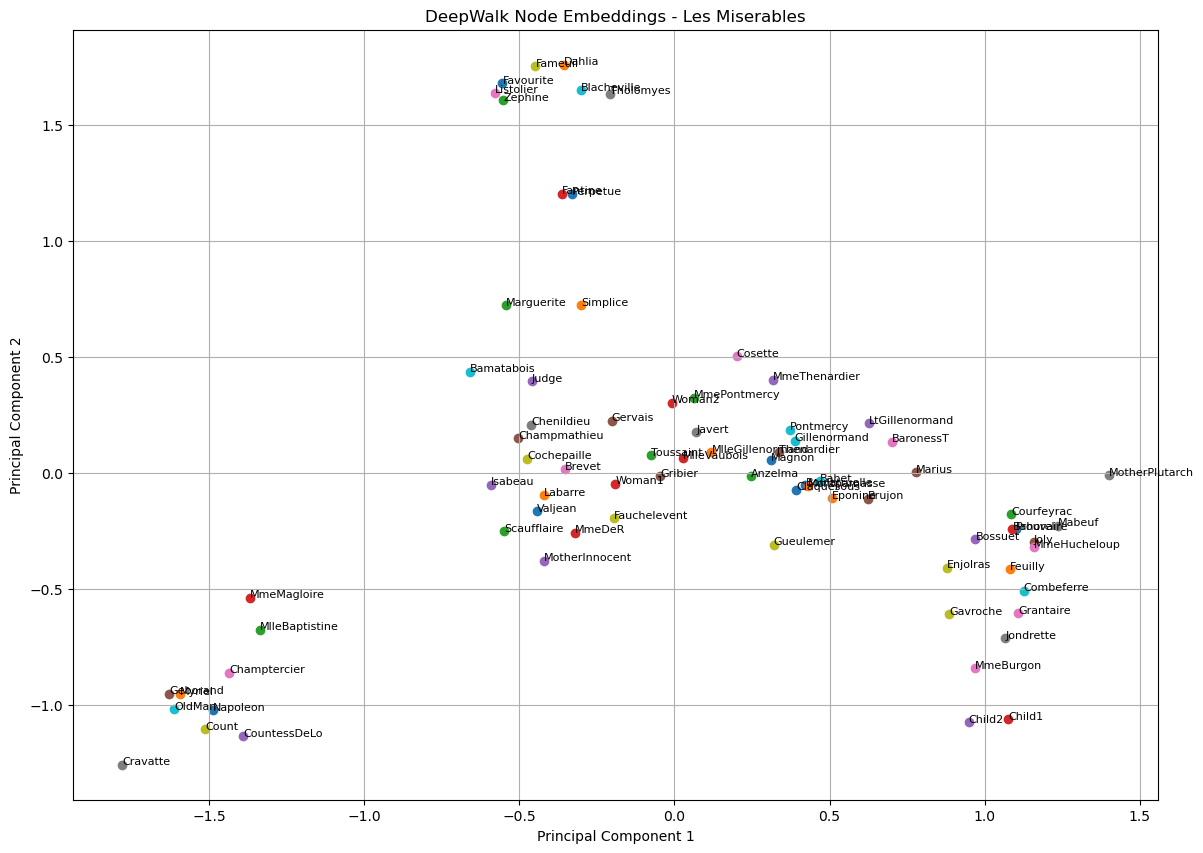

In [22]:



# Plot the embeddings
plt.figure(figsize=(14, 10))

for i, node in enumerate(embedding_df.index):

    x = embedding_2d[i, 0]
    y = embedding_2d[i, 1]

    plt.scatter(x, y)

    plt.annotate(
        node,
        (x, y),
        fontsize=8
    )

plt.title("DeepWalk Node Embeddings - Les Miserables")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.grid(True)

plt.show()

In [23]:
# Characters positioned close together have relatively similar learned representations in this embedding space.

# Characters positioned far apart have less similar representations.

# Groups of nearby points may indicate structural communities or similar network contexts.

In [25]:


#this code is to find the similar characters

from sklearn.metrics.pairwise import cosine_similarity

character = "Valjean"

target_vector = embeddings[character].reshape(1, -1)

similarities = {}

for node in G.nodes():

    if node != character:

        other_vector = embeddings[node].reshape(1, -1)

        score = cosine_similarity(
            target_vector,
            other_vector
        )[0][0]

        similarities[node] = score

similar_characters = sorted(
    similarities.items(),
    key=lambda x: x[1],
    reverse=True
)

print("Characters most similar to", character)

for name, score in similar_characters[:10]:

    print(name, ":", round(score, 4))

Characters most similar to Valjean
MmeDeR : 0.7399
Isabeau : 0.7043
MlleBaptistine : 0.6925
Scaufflaire : 0.692
Gervais : 0.6653
MmeMagloire : 0.6633
Cochepaille : 0.6583
Javert : 0.6572
Bamatabois : 0.639
MotherInnocent : 0.6273


In [26]:

# We can use a graph community-detection algorithm to assign colours to characters in the original 
# graph and in the embedding plot.

# We will use greedy modularity communities.


communities = list(
    nx.community.greedy_modularity_communities(G)
)

community_labels = {}

for community_id, community in enumerate(communities):

    for node in community:

        community_labels[node] = community_id

print("Number of detected communities:", len(communities))

Number of detected communities: 5


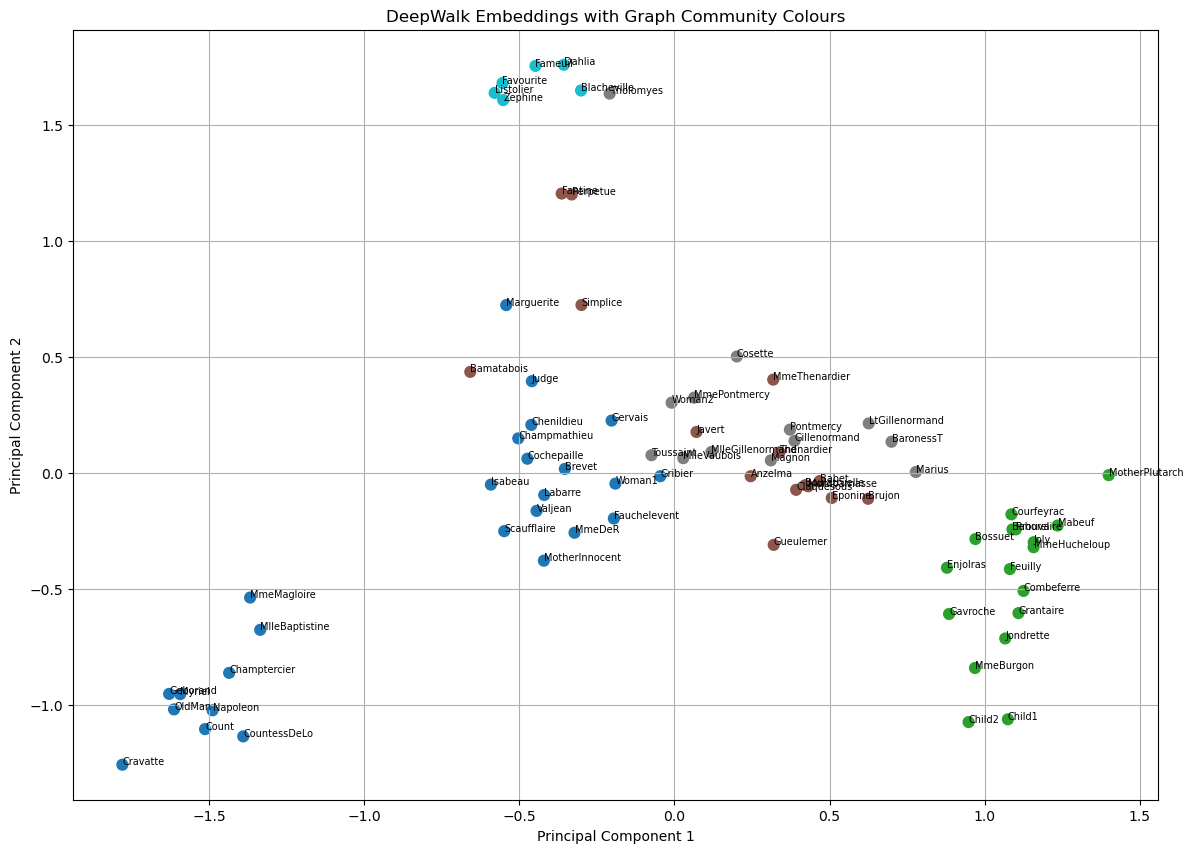

In [27]:
colors = [
    community_labels[node]
    for node in embedding_df.index
]

plt.figure(figsize=(14, 10))

plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    c=colors,
    cmap="tab10",
    s=60
)

for i, node in enumerate(embedding_df.index):

    plt.annotate(
        node,
        (embedding_2d[i, 0], embedding_2d[i, 1]),
        fontsize=7
    )

plt.title("DeepWalk Embeddings with Graph Community Colours")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.grid(True)

plt.show()

In [28]:
embedding_df.to_csv("les_miserables_embeddings.csv")

print("Embeddings saved successfully!")

Embeddings saved successfully!


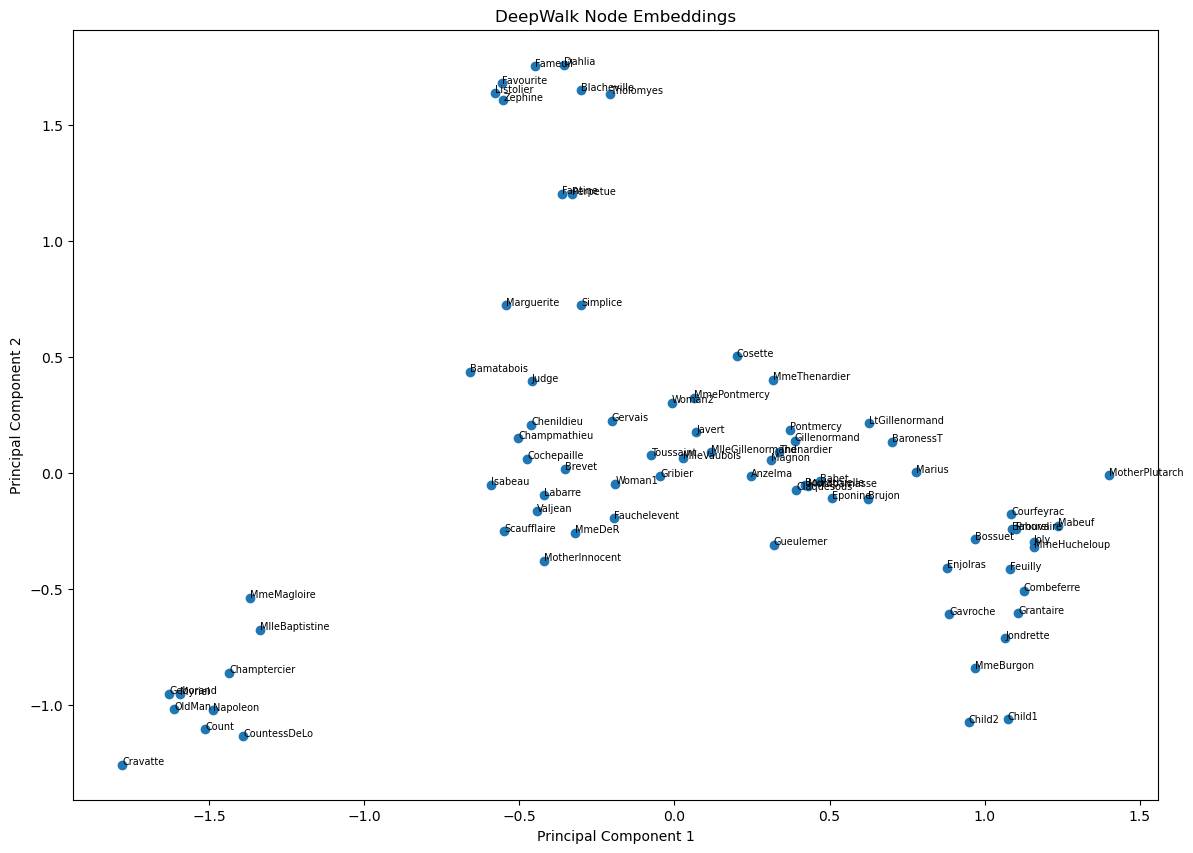

In [29]:
plt.figure(figsize=(14, 10))

plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1]
)

for i, node in enumerate(embedding_df.index):

    plt.annotate(
        node,
        (embedding_2d[i, 0], embedding_2d[i, 1]),
        fontsize=7
    )

plt.title("DeepWalk Node Embeddings")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.savefig(
    "deepwalk_embeddings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()